# Figure showing the mean change in an impact variable

In [16]:
import xarray as xr
import xagg as xa
import numpy as np
import pandas as pd
import geopandas as gpd
import os
import re
import glob
import copy
import string
import warnings
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
import matplotlib as mpl
from matplotlib import patches as mpatches
from cartopy import crs as ccrs
import cmocean
from scipy import stats as sstats

from funcs_support import get_filepaths,get_params,utility_print,load_shp
from funcs_readregs import coeffs_mortality,coeffs_gdppc,coeffs_payroll
from funcs_plot import plot_map,create_segcmap
dir_list = get_params()

extra_fonts = {'lato':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Regular.ttf'),
 'lato-bold':mpl.font_manager.FontProperties(fname=dir_list['aux']+'fonts/Lato-Bold.ttf')}


In [2]:
from distributed import Client

# Start dask client 
client = Client()
display(client)

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/8787/status,
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/8787/status,Workers: 2
Total threads: 2,Total memory: 10.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:38395,Workers: 0
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:39623,Total threads: 1
Dashboard: https://jupyterhub.hpc.ucar.edu/stable/user/schwarzwald/bcd_me_proc/proxy/35725/status,Memory: 5.00 GiB
Nanny: tcp://127.0.0.1:43559,


In [11]:
# Get filenames of impact projections
fns = get_filepaths(source_dir = 'impacts',dir_list = {'impacts':dir_list['proc']+'impact_projs/'})
fns = fns.query('freq == "agg"')
fns = fns.iloc[['crossfit' not in var for var in fns.varname.values]]
fns = fns.set_index(['varname','model']).sort_index()


gdf_insamp = gpd.read_file(dir_list['aux']+'geo_data/mortality_insamp_world_plugged.shp')

In [12]:

params_proc = {'mortality':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'mortality-interacted':{'varname':'tassumpoly','geo_typ':'impact-regions','shp_fn':'impact-region','popwght':False},
               'gdppc':{'varname':'tassumpoly','geo_typ':'adm1','shp_fn':'country-fixed','popwght':True},
               'payroll':{'varname':'tasmaxbinF','geo_typ':'adm2-us','shp_fn':'UScounties','popwght':True}}

imp_params = {'dmortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'dmortality-interacted':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
              'dgdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
              'dpayroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

idxs = {'impact-regions':{'hierid':'locid'},
        'adm1':{'CNTRY_NAME':'locid'},
        'adm2-us':{'FIPS':'locid'}}


nruns = {'dmortality':13,
         'dmortality-interacted':13,
         'dgdppc':13,
         'dpayroll':10}


In [13]:
cbar_params = {'mean':{'dmortality':{'vmin':-100,'vmax':100,'cmap':cmocean.cm.balance,'levels':21},
                   'dgdppc':{'vmin':-10,'vmax':10,'cmap':cmocean.cm.balance_r,'levels':21},
                   'dpayroll':{'vmin':-0.016,'vmax':0,'cmap':cmocean.cm.amp_r,'levels':17}},
               'std':{'dmortality':{'vmin':0,'vmax':50,'cmap':cmocean.cm.tempo,'levels':21},
                   'dgdppc':{'vmin':0,'vmax':10,'cmap':cmocean.cm.tempo,'levels':21},
                   'dpayroll':{'vmin':0,'vmax':0.008,'cmap':cmocean.cm.tempo,'levels':17}}}

In [14]:
nsamples = 1000
rng = np.random.default_rng()

colors = {'ERA5':'tab:red','JRA-3Q':'tab:orange','MERRA2':'tab:green','GMFD':'tab:blue','PRISM':'yellow','UDel':'yellow'}

#proc_names = {'mortality':'mortality rate [/100,000]',
#              'gdppc':'log GDP per capita growth',
#              'payroll':'payroll'}
proc_names = {'mortality':r'$\bf{All-cause\ mortality}$'+'\n'+r'$\bf{(Carleton\ et\ al.\ 2022)}$'+'\nmortality rate [/100,000]',
              'gdppc':r'$\bf{GDP\ per\ capita\ growth}$'+'\n'+r'$\bf{(Burke\ et\ al.\ 2015)}$'+'\nlog GDP per capita growth',
              'payroll':r'$\bf{Payroll}$'+'\n'+r'$\bf{(Behrer\ et\ al.\ 2021)}$'+'\npayroll'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke, Hsiang, and\nMiguel 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

proc_titles = {'mortality':'annual mortality rate',
               'gdppc':'GDP per capita growth',
               'payroll':'annual payroll'}
proc_xlims = {'mortality':[-15,45],
              'gdppc':[-2.5,32.5],
              'payroll':[70,115]}
proc_ylims = {'mortality':[-1,8],
              'gdppc':[-0.375,0.025],
              'payroll':[-0.00075,0.0001]}

def load_dmgfs(proc,load_kwargs = {},
              rng = rng,
              nsamples = nsamples):
    ''' Load MC'ed damage function, sampled at temperatures Tref

    Parameters
    ---------------
    proc : str
        Name of impact variable

    load_kwargs : dict
        Piped into `coeffs_*()`

    rng : numpy random generator

    nsamples : int
        Number of MC samples of VCV to use

    Returns
    ---------------
    dmgf : xr.DataArray
        `Tref` x `proj_base` x `sidx` datarray giving 
        coefficients at temperatures `Tref`


    '''
    
    # Load regression coefficients
    if proc == 'gdppc':
        coeffs,vcv = coeffs_gdppc(**load_kwargs)
    elif proc == 'mortality':
        coeffs,vcv = coeffs_mortality(**load_kwargs)
    elif proc == 'payroll':
        coeffs,vcv = coeffs_payroll(**load_kwargs)
    else:
        raise KeyError()

    coeffs = coeffs.dropna('proj_base',how='all')
    if 'proj_base_1' in vcv:
        vcv.dropna('proj_base_1').dropna('proj_base_2')
    else:
        vcv = vcv.dropna('proj_base',how='all')

    # Get MC samples of coefficients
    if 'proj_base_1' in vcv:
        # If jointly estimated across parameters
        coeffs_tmp = coeffs.coeffs.stack(predproj = ['pred','proj_base'])
        vcv_tmp = vcv.vcv.stack(predproj_1 = ['pred_1','proj_base_1'],
                                 predproj_2 = ['pred_2','proj_base_2'])
        
        coeffs_mvn = rng.multivariate_normal(coeffs_tmp,
                                             vcv_tmp,
                                             size=nsamples)
        
        coeffs_mvn = xr.DataArray(coeffs_mvn,
                                  dims = ['sidx','predproj'],
                                  coords = {'predproj':coeffs_tmp.predproj})
        coeffs_mvn = coeffs_mvn.unstack('predproj')
    else:
        # If separate fit for each proj_base
        coeffs_mvn = xr.apply_ufunc(rng.multivariate_normal,
                                   coeffs.coeffs,
                                   vcv.vcv,
                                   input_core_dims = [['pred'],['pred_1','pred_2']],
                                   output_core_dims = [['sidx','pred']],
                                   kwargs = {'size':nsamples},
                                           dask = 'parallelized',
                                           dask_gufunc_kwargs = {'output_sizes':{'sidx':nsamples}},
                                   vectorize=True)

    if np.any(['sumpoly' in k for k in coeffs_mvn.pred.values]):
        ts = np.arange(-20,51)
        var_stem = 'tassumpoly_'
        poly_degs = [int(re.split(var_stem,v)[-1]) for v in coeffs_mvn.pred.values if var_stem in v]
        t_vals = xr.DataArray(np.vstack([ts**k for k in poly_degs]),
                     dims = ['pred','bin_c'],
                     coords = {'pred':[v for v in coeffs_mvn.pred.values if var_stem in v],
                               'bin_c':ts})
    
        # Get damage function
        dmgf = (coeffs_mvn*t_vals).sum('pred')
        
        if proc == 'mortality':
            # Normalize over lowest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).min('bin_c')
        elif proc == 'gdppc':
            # Normalize over highest value
            dmgf = dmgf - dmgf.sel(bin_c = slice(10,30)).max('bin_c')
            #dmgf = dmgf - dmgf.sel(bin_c = 13)
        
        dmgf = dmgf.rename({'bin_c':'Tref'})
    elif 'bin' in coeffs_mvn.pred.values[0]:
        # Constructing the single-bin version
        dmgf = xr.apply_ufunc(rng.normal,
                   coeffs.isel(pred=0),
                   vcv.vcv.isel(pred_1 = 0,pred_2 = 0),
                   output_core_dims = [['sidx']],
                   vectorize=True,
                   kwargs = {'size':nsamples})
        
        dmgf = dmgf.expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                             125,5)})
        
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1])-20,
                                                                                   float(re.split(r'tasmaxbinF\_',str(coeffs.pred.values[0]))[-1]),
                                                                                   5)}),
                          dmgf],
                         dim='bin_f')
    
        dmgf = dmgf.rename({'bin_f':'Tref'}).coeffs
    elif 'days' in coeffs_mvn.pred.values[0]:
        dmgf = coeffs_mvn.expand_dims({'bin_f':np.arange(92.5, 125,5)}).isel(pred=0)
        dmgf = xr.concat([xr.zeros_like(dmgf.isel(bin_f=0,drop=True)).expand_dims({'bin_f':np.arange(92.5-20,
                                                                                           92.5,
                                                                                           5)}),
                                  dmgf],
                                 dim='bin_f')
        dmgf = dmgf.rename({'bin_f':'Tref'})

    return dmgf

def plot_dmgfs(dmgf,proc,ax=None,
               colors = colors,
               add_grid = True,
               proc_names = proc_names,
               proc_titles = proc_titles,
               proc_xlims = proc_xlims,
               proc_ylims = proc_ylims,
               simple = False):
    '''
    Damage function plotting code 

    '''

    if ax is None:
        ax = plt.subplot()
    
    for proj_base in dmgf.proj_base.values:
        plot_data = dmgf.sel(proj_base = proj_base)
        ax.fill_between(plot_data.Tref,
                        plot_data.quantile(0.025,dim='sidx'),
                        plot_data.quantile(0.975,dim='sidx'),
                        color=colors[proj_base],alpha=0.1)
        plot_data.mean('sidx').plot(color=colors[proj_base],linewidth=1,label=proj_base)
    
    
    ax.set_xlim(proc_xlims[proc])
    ax.set_ylim(proc_ylims[proc])

    if not simple:
        if add_grid:
            plt.grid()

    if simple:
        ax.set_xlabel('')
        ax.set_ylabel('')
        ax.set_title('')
    else:    
        ax.set_xlabel(r'Temperature')# [$^\circ$C]')
        ax.set_ylabel('Change in\n'+proc_names[proc])
        ax.set_title('Impact of day at T on\n'+proc_titles[proc])

    ax.axhline(0,color='k',linewidth=1)

    return ax 

/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1617: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/glade/u/home/schwarzwald/.conda/envs/impact_uncert/lib/python3.14/sit

/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure1.pdf saved!
/glade/u/home/schwarzwald/projects/impact_uncertainty/figures/Figure1.png saved!


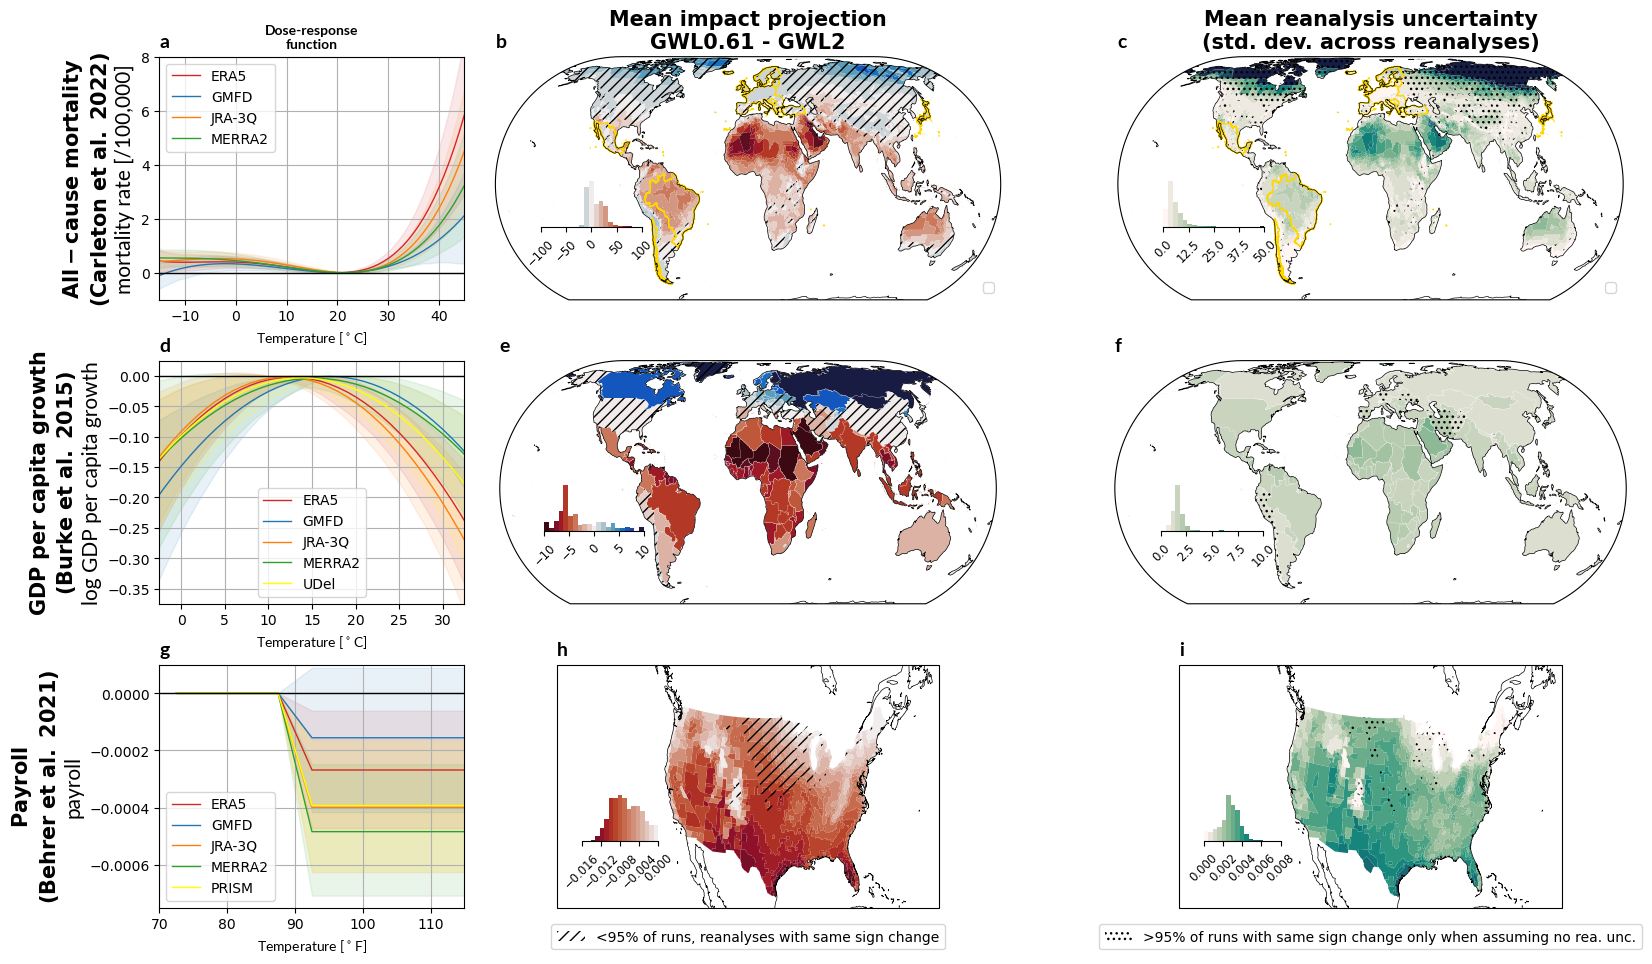

In [30]:
gwl = 2
keep_idvs_ref_gwl = 2
save_fig = True

projs = {'dmortality':ccrs.EckertIV(),
         'dgdppc':ccrs.EckertIV(),
         'dpayroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

for spread_typ in ['iqr']:#,'2sd']:
    if spread_typ == 'iqr':
        output_fn = f'{dir_list['figs']}Figure1'
    else:
        output_fn = f'{dir_list['figs']}extra_figs/Figure1_alt_wmaps_spread{spread_typ}'
    
    col_titles = {'mean':'Mean impact projection\nGWL0.61 - GWL'+str(gwl),
                  'std':'Mean reanalysis uncertainty\n(std. dev. across reanalyses)'}
    
    fig = plt.figure(figsize=(20,15))
    gs = plt.GridSpec(nrows=len(params_proc),
                      ncols=4,
                      width_ratios = [0.45,0.2,1,1],
                      hspace = 0.25,wspace=-0.2)
    
    for row_idx,var in enumerate(['dmortality','dgdppc','dpayroll']):
        proc = re.sub(r'^d','',var)
    
        #---------------------------
        # Plot damage function -----
        #---------------------------
        dmgf = load_dmgfs(proc)
    
        ax = fig.add_subplot(gs[row_idx,0])
    
        ax = plot_dmgfs(dmgf,proc,ax=ax)
    
        ax.annotate(string.ascii_lowercase[row_idx*3],(0,1.025),xycoords = 'axes fraction',
                    va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
    
        ax.legend()
    
        if row_idx == 0:
            ax.set_title('Dose-response\nfunction',fontsize=15,font=extra_fonts['lato-bold'])
        else:
            ax.set_title('')
    
        if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]',font=extra_fonts['lato'])
        elif proc in ['payroll']:
            ax.set_xlabel(r'Temperature [$^\circ$F]',font=extra_fonts['lato'])
    
        ax.set_ylabel(proc_names[proc],fontsize=15,font=extra_fonts['lato'])
        
    
        
        #---------------------------
        # Load impact data ---------
        #---------------------------
        dss = []
        for row in fns.loc[var].iterrows():
            with warnings.catch_warnings():
                # .done flag warning in zarr opening
                warnings.filterwarnings('ignore')
                ds_tmp = xr.open_zarr(row[1]['path'],consolidated=False)
            if ds_tmp.sizes['idv'] < nruns[var]:
                continue
            else:
                ds_tmp = ds_tmp.sel(imp_params[var],drop=True)
                
                # Drop all-na idvs
                keep_idvs = ds_tmp.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv
                ds_tmp = ds_tmp.sel(idv = keep_idvs.values)
                # Get the first x runs
                ds_tmp = ds_tmp.isel(idv = slice(0,nruns[var]))
        
                if ds_tmp.sizes['idv']<nruns[var]:
                    continue
                
                # Get mean over different obs products
                #ds_tmp = ds_tmp.mean(('proj_base'))
                ds_tmp['exprun'] = ds_tmp['experiment'].load()+ds_tmp['run'].load()
                ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            
                dss.append(ds_tmp)
                
        # Concat
        dss = xr.concat(dss,
                        dim='idv',
                        join='outer',
                        data_vars='minimal').load()
        
        dss['poly_idx'] = dss['locid']
        dss = dss.drop_vars('locid').rename({'poly_idx':'locid'})
    
        # Get locs with significant changes under obs uncertainty 
        # and without obs uncertainty (defined as mean +/- 2std 
        # diff from 0)
        if spread_typ == '2sd':
            sig_wobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).std(('proj_base','idv')) > 0)
            sig_noobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).mean('proj_base').std(('idv')) > 0)
        elif spread_typ == 'iqr':
            d = dss[var].sel(gwl=gwl)
            sig_wobs = d.quantile(0.025,('proj_base','idv'))/np.abs(d.quantile(0.025,('proj_base','idv'))) == d.quantile(0.975,('proj_base','idv'))/np.abs(d.quantile(0.975,('proj_base','idv')))
            sig_noobs = d.mean('proj_base').quantile(0.025,('idv'))/np.abs(d.mean('proj_base').quantile(0.025,('idv'))) == d.mean('proj_base').quantile(0.975,('idv'))/np.abs(d.mean('proj_base').quantile(0.975,('idv')))
    
        sigs = sig_wobs.astype(int)+sig_noobs.astype(int)
    
        
        #-------------------------------
        # Load corresponding shapefile -
        #-------------------------------
        gdf = load_shp(proc)
    
        #-------------------------------
        # Plot -------------------------
        #-------------------------------
        for col_idx,plot_typ in zip(np.arange(1,3),['mean','std']):
            #if params_proc[proc]['geo_typ'] == 'adm2-us':
            #    # Only use part of the horizontal grid spec for the smaller counties map
            #    ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=ccrs.PlateCarree())
            #else: 
            #ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=ccrs.PlateCarree())
            ax_map = fig.add_subplot(gs[row_idx,col_idx],projection=projs[var])
    
            if plot_typ == 'mean':
                plot_data = dss[var].sel(gwl=gwl).mean(('proj_base','idv'))
            elif plot_typ == 'std':
                plot_data = dss[var].sel(gwl=gwl).std('proj_base').mean('idv')

            if 'levels' in cbar_params[plot_typ][var]:
                gdf['colors'],bins,colors_ref = create_segcmap(plot_data.sel(locid = gdf.locid.values),
                                                cbar_params[plot_typ][var],return_all = True)
                gdf_tmp = gdf.dissolve(by='colors').reset_index()
                
                gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax_map)
                # Plot national boundaries at least
                if proc == 'gdppc':
                    gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())
                    
            else:
                fig,ax_map = plot_map(plot_data.sel(locid = gdf.locid.values),
                     gdf,**cbar_params[plot_typ][var],fig=fig,ax=ax_map)
    
            # Plot hatching
            gdf_tmp = gdf.copy()
            sigs = sigs.sel(locid = gdf_tmp.locid.values)
            if plot_typ == 'mean':
                gdf_tmp['tohatch'] = (sigs < 2)
                hatch = '///'
                if spread_typ == 'iqr':
                    label = r'<95% of runs, reanalyses with same sign change' 
                elif spread_typ == '2sd':
                    label = r'$|\mu \pm 2\sigma|<0$ with reanalysis spread'
                    
            elif plot_typ == 'std':
                gdf_tmp['tohatch'] = (sigs == 1)
                hatch = '...'
                if spread_typ == 'iqr':
                    label = r'>95% of runs with same sign change only when assuming no rea. unc.'
                elif spread_typ == '2sd':
                    label = r'$|\mu \pm 2\sigma|>0$ only w/o reanalysis spread'
                    
            gdf_tmp = gdf_tmp.where(gdf_tmp.tohatch).dissolve()
            gdf_tmp.plot(facecolor='none',
                         edgecolor='black',linewidth=0, # doesn't plot with no edgecolor
                         hatch=hatch,
                         transform=ccrs.PlateCarree(),
                         ax=ax_map)
            if row_idx == 2:
                ax_map.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                                   hatch=hatch, label=label)],
                          bbox_to_anchor = [0.5,-0.2],loc='lower center')
        
            ax_map.coastlines(linewidth=0.5)

            if proc == 'mortality':
                gdf_insamp.plot(edgecolor='gold',facecolor='none',transform=ccrs.PlateCarree(),label='Regression in-sample',
                               ax=ax_map)
                ax_map.legend(loc='lower right')
    
            if row_idx == 0:
                ax_map.set_title(col_titles[plot_typ],fontsize=15,fontweight='bold')
            else:
                ax_map.set_title('')
    
            if var == 'dpayroll':
                ax_map.set_extent((-142.5, -64, 23.7, 50.6),
                              crs = ccrs.PlateCarree())

            # Subplot labeling
            ax_map.annotate(string.ascii_lowercase[row_idx*3+col_idx]+'',(0,1.025),xycoords = 'axes fraction',
                                        va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
        
            #---- Inset colorbar histogram
            if 'levels' in cbar_params[plot_typ][var]:
                nbins = cbar_params[plot_typ][var]['levels']
            else:
                nbins = 20
            if var == 'dpayroll':
                ax = ax_map.inset_axes([0.065, 0.275, 0.2, 0.2], xticks=[], yticks=[])
            else:
                ax = ax_map.inset_axes([0.09, 0.3, 0.2, 0.2], xticks=[], yticks=[])
            
            N, bins, patches = (plot_data.clip(min=cbar_params[plot_typ][var]['vmin'],
                                               max=cbar_params[plot_typ][var]['vmax']).
                                plot.hist(bins=bins,ax=ax))
            
            for binid, patch in enumerate(patches):
                #patch.set_facecolor(cbar_params[plot_typ][var]['cmap'](np.arange(0,1,1/nbins))[binid,:])
                patch.set_facecolor(colors_ref[binid])
            
            for side in ['top','left','right']:
                ax.spines[side].set_visible(False)
            ax.set_xticks(np.arange(cbar_params[plot_typ][var]['vmin'],
                                    cbar_params[plot_typ][var]['vmax']+0.0000001,
                                    (cbar_params[plot_typ][var]['vmax'] - 
                                     cbar_params[plot_typ][var]['vmin'])/4))
            ax.set_xlim(cbar_params[plot_typ][var]['vmin'],
                        cbar_params[plot_typ][var]['vmax'])
            ax.set_yticks([])
            ax.set_ylabel('')
            ax.set_xlabel('')
            ax.set_title('')
            ax.tick_params(axis='x',labelrotation=45,labelsize='small')

            # Remove axis background from inset histogram
            ax.set_facecolor('none')
    
            

    if save_fig:
        utility_print(output_fn)


## Version with global summary distributions with and without reanalysis uncertainty 

In [9]:
imp_params = {'mortality':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg','spec':'pooled','indflag':'noInd'},
                      'gdppc':{'timeframe':'1980-2010','obstreat':'sep','resolution':'025deg'},
                      'payroll':{'timeframe':'1986-2008','obstreat':'sep','resolution':'025deg','weighting':'pop'}}

# Load impacts projections

dists = {}
for proc in ['mortality','gdppc','payroll']:
    #--------------------------
    # Load --------------------
    #--------------------------
    if proc == 'mortality':
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}_agg_*ALLGWL*.zarr'))
    else:
        # Get crossfits
        fns = np.sort(glob.glob(f'{dir_list['proc']}impact_projs/{proc}/d{proc}-crossfit_agg_*ALLGWL*.zarr'))
    def load_impact(fn):
        ds_tmp = xr.open_zarr(fn,consolidated=False)
        ds_tmp = ds_tmp.set_coords('locid') # Should be coordinate, instead of concatenated variable
        ds_tmp = ds_tmp.assign_coords({'model':(('idv'),[re.split(r'\_',re.split(r'\/',fn)[-1])[2]]*ds_tmp.sizes['idv'])})
    
        ds_tmp['exprun'] = ds_tmp['experiment']+ds_tmp['run']
        if 'idv' in ds_tmp.coords:
            ds_tmp = ds_tmp.reset_index('idv')
        ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
        return ds_tmp
    
    with warnings.catch_warnings():
        # Silence zarr warnings related to the /.done flags used
        warnings.filterwarnings('ignore')
        dss = xr.concat([load_impact(fn) for fn in fns],
                    dim='idv',join='outer')
    
    if proc == 'mortality':
        dss = dss.sel(imp_params[proc])
    dss = dss.sel(gwl=[0.61,2])
    dss = dss.reset_index('idv').set_index(idv = ['model','exprun']).drop_vars(['experiment','run'])
    dss = dss.set_index(poly_idx='locid').rename({'poly_idx':'locid'})
    
    # Figure out how many BCD-ME members reach a given GWL
    # (copy.deepcopy() necessary as a workaround around a numpy bug
    # affecting the unstack a few lines down that's triggered 
    # indirectly by the reset_index here)
    gwl_counter = copy.deepcopy(dss.maxgwl).load().reset_index('idv').groupby(['model','maxgwl']).count()
    gwl_counter = gwl_counter.sel(maxgwl = gwl_counter.maxgwl.values[::-1]).cumsum('maxgwl')
    
    #---------------------------
    # Get the balanced panel from 
    # the main text figures
    #---------------------------
    max_gwl = 3
    if proc == 'payroll':
        nruns = 10
    else:
        nruns = 13
    
    gwlmods = gwl_counter.sel(maxgwl=3)
    proc_mods = gwlmods.isel(model = gwlmods>=nruns).model.values
    
    dss_tmp = dss.isel(idv = dss.maxgwl.load()>=max_gwl).groupby('model').map(lambda x: x.isel(idv=slice(0, nruns)))
    dss_tmp = dss_tmp.isel(idv=[m in proc_mods for m in dss_tmp.model.values]).chunk({'idv':-1})
    dss_tmp = dss_tmp.unstack('idv')['d'+proc]
    dss_tmp = dss_tmp.chunk({'model':-1,'exprun':-1}).unify_chunks()
    
    #---------------------------
    # Calc changes
    #---------------------------
    ddss_tmp = dss_tmp.sel(gwl=2) - dss_tmp.sel(gwl=0.61)
    ddss_tmp2 = ddss_tmp.stack(idv = ['model','exprun']).dropna('idv',how='all').load()

    #---------------------------
    # Calc aggregated changes
    #---------------------------
    # Get weights (population or dividends)
    if proc == 'mortality':
        allpreds = xr.open_zarr(dir_list['proc']+'aux/all_preds.zarr')
        pop = allpreds.pop.sel(ageset='agetotal',pred_ssp='ssp3',pred_model='high',gwl=0.61).mean('year').compute()
        pop = pop.rename({'hierid':'locid'}) 
    elif proc == 'gdppc':
        pop = load_shp('gdppc').loc[:,('locid','POP_CNTRY')]
        pop = pop.set_index('locid').to_xarray().POP_CNTRY
    elif proc == 'payroll':
        pop = pd.read_csv(dir_list['aux']+'hle_replication_data.csv').groupby('fips')['Dividends'].mean()
        pop = pop.to_xarray().rename({'fips':'locid'})
        pop['locid'] = [str(fips).zfill(5) for fips in pop.locid.values]
    # Get aggregated values 
    dists[proc] = ((ddss_tmp2*pop).sum('locid')/pop.sum('locid'))

In [ ]:
gwl = 2
keep_idvs_ref_gwl = 2
save_fig = True

add_rea_guides = False

projs = {'dmortality':ccrs.EckertIV(),
         'dgdppc':ccrs.EckertIV(),
         'dpayroll':ccrs.AlbersEqualArea(central_longitude=-100,central_latitude=35)}

test_locs = {'mortality':np.arange(0,40,0.25),
             'gdppc':np.arange(-8,2,0.05),
             'payroll':np.arange(-0.02,0.005,0.0005)}

labels = {'mortality':{'all':'All BCD-ME reanalyses',
                       'ref':'GMFD (Carleton et al.)'},
          'gdppc':{'all':'All BCD-ME reanalyses',
                   'ref':'UDel (Burke et al.)'},
                   #'ref':"UDel (Burke et al.)\nx mean of BCD-ME rea's"},
          'payroll':{'all':'All BCD-ME reanalyses',
                     'ref':'PRISM (Behrer et al.)'}}
                     #'ref':"PRISM (Behrer et al.)\nx mean of BCD-ME rea's"}}

xlabels = {'mortality':'Change in mortality rate [1/100,000]',
           'gdppc':'Change in log GDP per capita growth',
           'payroll':'Fractional change in annual payroll'}

proc_full_names = {'mortality':'All-cause mortality\n(Carleton et al. 2022)',
                           'gdppc':'GDP per capita growth\n(Burke et al. 2015)',
                           'payroll':'Payroll\n(Behrer et al., 2021)'}

for spread_typ in ['iqr']:#,'2sd']:
    if spread_typ == 'iqr':
        output_fn = f'{dir_list['figs']}Figure1_wkde'
    else:
        output_fn = f'{dir_list['figs']}extra_figs/Figure1_wkde_alt_wmaps_spread{spread_typ}'
    
    col_titles = {'mean':'Mean impact projection\nGWL0.61 - GWL'+str(gwl),
                  'std':'Mean reanalysis uncertainty\n(std. dev. across reanalyses)'}
    
    fig = plt.figure(figsize=(20,15))
    gs = plt.GridSpec(nrows=len(params_proc),
                      ncols=4,
                      width_ratios = [0.45,0,1,0.6],
                      hspace = 0.25,wspace=-0.05)
    
    for row_idx,var in enumerate(['dmortality','dgdppc','dpayroll']):
        proc = re.sub(r'^d','',var)
    
        #---------------------------
        # Plot damage function -----
        #---------------------------
        dmgf = load_dmgfs(proc)
    
        ax = fig.add_subplot(gs[row_idx,0])
    
        ax = plot_dmgfs(dmgf,proc,ax=ax)
    
        ax.annotate(string.ascii_lowercase[row_idx*3],(0,1.025),xycoords = 'axes fraction',
                    va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
    
        ax.legend()
    
        if row_idx == 0:
            ax.set_title('Dose-response\nfunction',font=extra_fonts['lato-bold'],fontsize=15)
        else:
            ax.set_title('')
    
        if proc in ['mortality','gdppc']:
            ax.set_xlabel(r'Temperature [$^\circ$C]',font=extra_fonts['lato'])
        elif proc in ['payroll']:
            ax.set_xlabel(r'Temperature [$^\circ$F]',font=extra_fonts['lato'])
    
        ax.set_ylabel(proc_names[proc],fontsize=15,font=extra_fonts['lato'])
        
    
        
        #---------------------------
        # Load impact data ---------
        #---------------------------
        dss = []
        for row in fns.loc[var].iterrows():
            with warnings.catch_warnings():
                # .done flag warning in zarr opening
                warnings.filterwarnings('ignore')
                ds_tmp = xr.open_zarr(row[1]['path'],consolidated=False)
            if ds_tmp.sizes['idv'] < nruns[var]:
                continue
            else:
                ds_tmp = ds_tmp.sel(imp_params[var],drop=True)
                
                # Drop all-na idvs
                keep_idvs = ds_tmp.sel(gwl=keep_idvs_ref_gwl).dropna('idv',how='all').idv
                ds_tmp = ds_tmp.sel(idv = keep_idvs.values)
                # Get the first x runs
                ds_tmp = ds_tmp.isel(idv = slice(0,nruns[var]))
        
                if ds_tmp.sizes['idv']<nruns[var]:
                    continue
                
                # Get mean over different obs products
                #ds_tmp = ds_tmp.mean(('proj_base'))
                ds_tmp['exprun'] = ds_tmp['experiment'].load()+ds_tmp['run'].load()
                ds_tmp = ds_tmp.set_index(idv = ['model','exprun'])
            
                dss.append(ds_tmp)
                
        # Concat
        dss = xr.concat(dss,
                        dim='idv',
                        join='outer',
                        data_vars='minimal').load()
        
        dss['poly_idx'] = dss['locid']
        dss = dss.drop_vars('locid').rename({'poly_idx':'locid'})
    
        # Get locs with significant changes under obs uncertainty 
        # and without obs uncertainty (defined as mean +/- 2std 
        # diff from 0)
        if spread_typ == '2sd':
            sig_wobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).std(('proj_base','idv')) > 0)
            sig_noobs = (np.abs(dss[var].sel(gwl=gwl).mean(('proj_base','idv'))) - 2*dss[var].sel(gwl=gwl).mean('proj_base').std(('idv')) > 0)
        elif spread_typ == 'iqr':
            d = dss[var].sel(gwl=gwl)
            sig_wobs = d.quantile(0.025,('proj_base','idv'))/np.abs(d.quantile(0.025,('proj_base','idv'))) == d.quantile(0.975,('proj_base','idv'))/np.abs(d.quantile(0.975,('proj_base','idv')))
            sig_noobs = d.mean('proj_base').quantile(0.025,('idv'))/np.abs(d.mean('proj_base').quantile(0.025,('idv'))) == d.mean('proj_base').quantile(0.975,('idv'))/np.abs(d.mean('proj_base').quantile(0.975,('idv')))
    
        sigs = sig_wobs.astype(int)+sig_noobs.astype(int)
    
        
        #-------------------------------
        # Load corresponding shapefile -
        #-------------------------------
        gdf = load_shp(proc)
    
        #-------------------------------
        # Plot mean change map ---------
        #-------------------------------
        for col_idx,plot_typ in zip(np.arange(2,3),['mean']):
            #if params_proc[proc]['geo_typ'] == 'adm2-us':
            #    # Only use part of the horizontal grid spec for the smaller counties map
            #    ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+3)],projection=ccrs.PlateCarree())
            #else: 
            #ax_map = fig.add_subplot(gs[row_idx,(col_idx*4):(col_idx*4+4)],projection=ccrs.PlateCarree())
            ax_map = fig.add_subplot(gs[row_idx,col_idx],projection=projs[var])
    
            if plot_typ == 'mean':
                plot_data = dss[var].sel(gwl=gwl).mean(('proj_base','idv'))
            elif plot_typ == 'std':
                plot_data = dss[var].sel(gwl=gwl).std('proj_base').mean('idv')

            if 'levels' in cbar_params[plot_typ][var]:
                gdf['colors'],bins,colors_ref = create_segcmap(plot_data.sel(locid = gdf.locid.values),
                                                cbar_params[plot_typ][var],return_all = True)
                gdf_tmp = gdf.dissolve(by='colors').reset_index()
                
                gdf_tmp.plot(color=gdf_tmp.colors,edgecolor='none',transform=ccrs.PlateCarree(),ax=ax_map)
                # Plot national boundaries at least
                if proc == 'gdppc':
                    gdf.plot(ax=ax_map,facecolor='none',edgecolor='w',linewidth=0.1,transform=ccrs.PlateCarree())
                    
            else:
                fig,ax_map = plot_map(plot_data.sel(locid = gdf.locid.values),
                     gdf,**cbar_params[plot_typ][var],fig=fig,ax=ax_map)
    
            # Plot hatching
            gdf_tmp = gdf.copy()
            sigs = sigs.sel(locid = gdf_tmp.locid.values)
            
            gdf_tmp['tohatch'] = (sigs == 1)
            hatch = '///'
            if spread_typ == 'iqr':
                label = r'>95% of runs with same sign change only when assuming no rea. unc.'
            elif spread_typ == '2sd':
                label = r'$|\mu \pm 2\sigma|>0$ only w/o reanalysis spread'
                    
            gdf_tmp = gdf_tmp.where(gdf_tmp.tohatch).dissolve()
            gdf_tmp.plot(facecolor='none',
                         edgecolor='black',linewidth=0, # doesn't plot with no edgecolor
                         hatch=hatch,
                         transform=ccrs.PlateCarree(),
                         ax=ax_map)
            if row_idx == 2:
                ax_map.legend(handles=[mpatches.Patch(facecolor='none', edgecolor='k', linewidth=0,
                                                   hatch=hatch, label=label)],
                          bbox_to_anchor = [0.5,-0.2],loc='lower center')
        
            ax_map.coastlines(linewidth=0.5)

            if proc == 'mortality':
                gdf_insamp.plot(edgecolor='gold',facecolor='none',transform=ccrs.PlateCarree(),label='Regression in-sample',
                               ax=ax_map)
                ax_map.legend(handles=[mpatches.Patch(ec='gold',fc='w',label='Regression in-sample')],
                              loc='lower right')
    
            if row_idx == 0:
                ax_map.set_title(col_titles[plot_typ],font=extra_fonts['lato-bold'],fontsize=15)
            else:
                ax_map.set_title('')
    
            if var == 'dpayroll':
                ax_map.set_extent((-142.5, -64, 23.7, 50.6),
                              crs = ccrs.PlateCarree())

            # Subplot labeling
            ax_map.annotate(string.ascii_lowercase[row_idx*3+col_idx]+'',(0,1.025),xycoords = 'axes fraction',
                                        va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
        
            #---- Inset colorbar histogram
            if 'levels' in cbar_params[plot_typ][var]:
                nbins = cbar_params[plot_typ][var]['levels']
            else:
                nbins = 20
            if var == 'dpayroll':
                ax = ax_map.inset_axes([0.065, 0.275, 0.2, 0.2], xticks=[], yticks=[])
            else:
                ax = ax_map.inset_axes([0.09, 0.3, 0.2, 0.2], xticks=[], yticks=[])
            
            N, bins, patches = (plot_data.clip(min=cbar_params[plot_typ][var]['vmin'],
                                               max=cbar_params[plot_typ][var]['vmax']).
                                plot.hist(bins=bins,ax=ax))
            
            for binid, patch in enumerate(patches):
                #patch.set_facecolor(cbar_params[plot_typ][var]['cmap'](np.arange(0,1,1/nbins))[binid,:])
                patch.set_facecolor(colors_ref[binid])
            
            for side in ['top','left','right']:
                ax.spines[side].set_visible(False)
            ax.set_xticks(np.arange(cbar_params[plot_typ][var]['vmin'],
                                    cbar_params[plot_typ][var]['vmax']+0.0000001,
                                    (cbar_params[plot_typ][var]['vmax'] - 
                                     cbar_params[plot_typ][var]['vmin'])/4))
            ax.set_xlim(cbar_params[plot_typ][var]['vmin'],
                        cbar_params[plot_typ][var]['vmax'])
            ax.set_yticks([])
            ax.set_ylabel('')
            ax.set_xlabel('')
            ax.set_title('')
            ax.tick_params(axis='x',labelrotation=45,labelsize='small')

            # Remove axis background from inset histogram
            ax.set_facecolor('none')

        #-------------------------------
        # Plot KDEs --------------------
        #-------------------------------
        ax = fig.add_subplot(gs[row_idx,-1])

        # Make KDEs of distributions
        kde = {'all':sstats.gaussian_kde(dists[proc].values.flatten())}
        if proc == 'mortality':
            kde = {'all':sstats.gaussian_kde(dists[proc].values.flatten())}
            kde['ref'] = sstats.gaussian_kde(dists[proc].sel(proj_base='GMFD').values.flatten())
        else:
            # Recover just the matching fit and projected reanalyses
            dist_tmp = dists[proc].where(dists[proc].fit_mod == dists[proc].proj_base).stack(mods = ['fit_mod','proj_base']).dropna('mods',how='all')
            kde = {'all':sstats.gaussian_kde(dist_tmp.values.flatten())}
            if proc == 'gdppc':
                kde['ref'] = sstats.gaussian_kde(dists[proc].sel(fit_mod='UDel').mean('proj_base').values.flatten())
            elif proc == 'payroll':
                kde['ref'] = sstats.gaussian_kde(dists[proc].sel(fit_mod='PRISM').mean('proj_base').values.flatten())
        kdet = {typ:k(test_locs[proc]) for typ,k in kde.items()}
        kdet = {typ:k/k.sum() for typ,k in kdet.items()}
    
    
        # Plot
        h0 = ax.fill_between(test_locs[proc],kdet['all'],color='tab:red',alpha=0.4,label=labels[proc]['all'])
        h1 = ax.fill_between(test_locs[proc],kdet['ref'],color='tab:blue',alpha=0.4,label=labels[proc]['ref'])
    
        # Show UDel / PRISM vs. each of the individual bias-corrected and downscaled prods
        if add_rea_guides and proc != 'mortality':
            for proj_base in dists[proc].proj_base.values:
                kde_tmp = sstats.gaussian_kde(dists[proc].sel(fit_mod=('PRISM' if proc == 'payroll' else 'UDel'),proj_base=proj_base).values.flatten())
                kde_tmp = kde_tmp(test_locs[proc])
                kde_tmp = kde_tmp/kde_tmp.sum()
                h2 = ax.plot(test_locs[proc],kde_tmp,linewidth=0.5,linestyle='--',color='k',
                             label='UDel x each BCD-ME rea.')
                h2 = h2[0]
        # Annotations
        if row_idx == 0:
            ax.set_title('Global weighted mean impact projection\nGWL0.61 - GWL2',
                         font=extra_fonts['lato-bold'],fontsize=15)
        else:
            ax.set_title('')
        ax.set_xlabel(xlabels[proc])
        ax.set_ylim(ax.get_ylim()[0],ax.get_ylim()[1]+0.2*(ax.get_ylim()[1]-ax.get_ylim()[0]))
        if row_idx == 0:
            ax.legend(title='KDEs across GCMs and runs, with:')
        else:
            if add_rea_guides:
                ax.legend([h1,h2],
                          [h1.get_label(),h2.get_label()])
            else:
                ax.legend([h1],[h1.get_label()])
        ax.set_yticks([])
    
        ax.set_ylabel('Normalized density')

        # Subplot labeling
        ax.annotate(string.ascii_lowercase[row_idx*3+col_idx]+'',(0,1.025),xycoords = 'axes fraction',
                                        va = 'bottom',font=extra_fonts['lato-bold'],fontsize=14)
    

    if save_fig:
        utility_print(output_fn)


### Fixing in-sample shapefile

In [6]:
gdf_insamp = gpd.read_file('../aux_data/geo_data/mortality_insample_world.shp').to_crs('EPSG:4326')
gdf_insamp = gdf_insamp.query('(iso != "IND") and (iso != "USA") and (iso != "CHN")')
gdf_insamp['geometry'] = gdf_insamp.make_valid()             

In [44]:
gdf_insamp.dissolve().boundary

0    MULTILINESTRING ((-114.72283 18.35228, -114.73...
dtype: geometry

In [46]:
gdf_insamp.dissolve().exterior

0    None
dtype: geometry

In [14]:
from shapely.geometry import MultiPolygon, Polygon


def remove_interiors(poly):
    """
    Close polygon holes by limitation to the exterior ring.

    Arguments
    ---------
    poly: shapely.geometry.Polygon
        Input shapely Polygon

    Returns
    ---------
    Polygon without any interior holes
    """
    if poly.interiors:
        return Polygon(list(poly.exterior.coords))
    else:
        return poly


def pop_largest(gs):
    """
    Pop the largest polygon off of a GeoSeries

    Arguments
    ---------
    gs: geopandas.GeoSeries
        Geoseries of Polygon or MultiPolygon objects

    Returns
    ---------
    Largest Polygon in a Geoseries
    """
    geoms = [g.area for g in gs]
    return gs.pop(geoms.index(max(geoms)))


def close_holes(geom):
    """
    Remove holes in a polygon geometry

    Arguments
    ---------
    gseries: geopandas.GeoSeries
        Geoseries of Polygon or MultiPolygon objects

    Returns
    ---------
    Largest Polygon in a Geoseries
    """
    if isinstance(geom, MultiPolygon):
        ser = gpd.GeoSeries([remove_interiors(g) for g in geom.geoms])
        big = pop_largest(ser)
        outers = ser.loc[~ser.within(big)].tolist()
        if outers:
            return MultiPolygon([big] + outers)
        return Polygon(big)
    if isinstance(geom, Polygon):
        return remove_interiors(geom)

gdf_insamp = gpd.GeoSeries(gdf_insamp.union_all()).geometry.apply(lambda p: close_holes(p))
gdf_insamp = gpd.GeoSeries(gdf_insamp,crs='EPSG:4326')

In [25]:
gdf_insamp.to_file(dir_list['aux']+'geo_data/mortality_insamp_world_plugged.shp')